# Tech Challenge Fase 1 — Case NPS Preditivo
## 02 — Análise Exploratória de Dados (EDA)

**Grupo:** Gustavo Mainchein, Gustavo Lopes, Gustavo Valentim, Luana Barbosa

**Objetivo desta etapa:** entender, com foco em negócio, quais fatores operacionais mais influenciam a satisfação do cliente (NPS), identificar o "ponto de ruptura" da experiência e traçar o perfil de clientes promotores e detratores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.width', 140)
plt.rcParams.update({
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

TEAL, NAVY, GREY, RED = "#0E7C7B", "#1B2A4A", "#9AA5B1", "#C0392B"

df = pd.read_csv("../data/desafio_nps_fase_1.csv")
df.head()

Matplotlib is building the font cache; this may take a moment.


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 1. Entendimento inicial dos dados

Antes de qualquer cruzamento, checamos volume, tipos de dados e qualidade (nulos e duplicados) — etapa de *Data Understanding* do CRISP-DM.

In [2]:
print("Dimensões:", df.shape)
print()
print(df.dtypes)
print()
print("Valores nulos por coluna:")
print(df.isna().sum())
print()
print("Duplicados (customer_id):", df["customer_id"].duplicated().sum())

Dimensões: (2500, 19)

customer_id                    int64
customer_age                   int64
customer_region                  str
customer_tenure_months         int64
order_id                       int64
order_value                  float64
items_quantity                 int64
discount_value               float64
payment_installments           int64
delivery_time_days             int64
delivery_delay_days            int64
freight_value                float64
delivery_attempts              int64
customer_service_contacts      int64
resolution_time_days           int64
nps_score                    float64
repeat_purchase_30d            int64
complaints_count               int64
csat_internal_score          float64
dtype: object

Valores nulos por coluna:
customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value  

**Achado:** a base tem 2.500 pedidos, sem valores nulos e sem duplicidade de `customer_id`. Isso significa que não é necessário tratamento de imputação — podemos seguir diretamente para a análise.

## 2. Criando a variável categórica de NPS

Seguindo a metodologia padrão de NPS, segmentamos a nota (0–10) em três grupos: **Detrator (0–6)**, **Neutro (7–8)** e **Promotor (9–10)**.

In [3]:
def nps_categoria(nota):
    if nota <= 6:
        return "Detrator"
    elif nota <= 8:
        return "Neutro"
    else:
        return "Promotor"

df["nps_categoria"] = df["nps_score"].apply(nps_categoria)
ordem = ["Detrator", "Neutro", "Promotor"]
cores = [RED, GREY, TEAL]

contagem = df["nps_categoria"].value_counts()[ordem]
percentual = df["nps_categoria"].value_counts(normalize=True)[ordem] * 100
print(contagem)
print(percentual.round(1))

nps_classico = percentual["Promotor"] - percentual["Detrator"]
print(f"\nNPS clássico da base (%Promotor - %Detrator): {nps_classico:.1f}")

nps_categoria
Detrator    1851
Neutro       448
Promotor     201
Name: count, dtype: int64
nps_categoria
Detrator    74.0
Neutro      17.9
Promotor     8.0
Name: proportion, dtype: float64

NPS clássico da base (%Promotor - %Detrator): -66.0


**Achado central:** apenas **8% dos clientes são promotores**, enquanto **74% são detratores** — um NPS clássico de **-66**, extremamente negativo. Isso confirma, com dados, a dor de negócio descrita no case: a empresa tem um problema sério e generalizado de satisfação, não incidentes isolados.

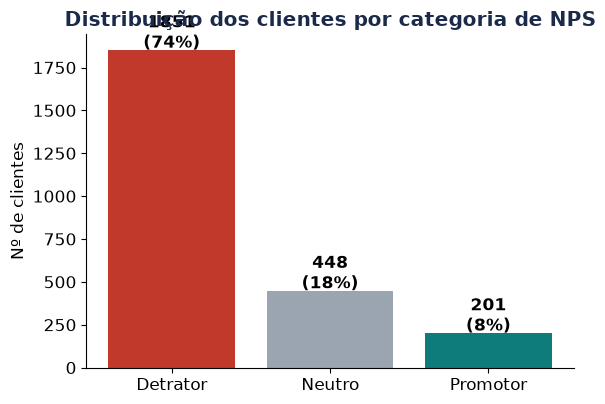

In [4]:
fig, ax = plt.subplots(figsize=(6,4.2))
barras = ax.bar(ordem, contagem.values, color=cores)
for b, v in zip(barras, contagem.values):
    ax.text(b.get_x()+b.get_width()/2, v+15, f"{v}\n({v/len(df)*100:.0f}%)", ha="center", fontweight="bold")
ax.set_ylabel("Nº de clientes")
ax.set_title("Distribuição dos clientes por categoria de NPS", fontweight="bold", color=NAVY)
plt.tight_layout()
plt.savefig("../reports/01_distribuicao_nps.png", dpi=150)
plt.show()

## 3. Quais fatores mais se correlacionam com a satisfação?

Calculamos a correlação de Pearson entre `nps_score` e as variáveis numéricas de pedido, logística e atendimento.

In [5]:
num_cols = ["customer_age","customer_tenure_months","order_value","items_quantity","discount_value",
            "payment_installments","delivery_time_days","delivery_delay_days","freight_value",
            "delivery_attempts","customer_service_contacts","resolution_time_days","complaints_count"]

corr = df[num_cols + ["nps_score"]].corr()["nps_score"].drop("nps_score").sort_values()
print(corr)

delivery_delay_days         -0.597260
complaints_count            -0.496800
customer_service_contacts   -0.350845
resolution_time_days        -0.191392
freight_value               -0.041087
customer_age                -0.009936
customer_tenure_months      -0.009711
delivery_time_days           0.000925
items_quantity               0.011468
payment_installments         0.023718
discount_value               0.025104
delivery_attempts            0.027680
order_value                  0.036990
Name: nps_score, dtype: float64


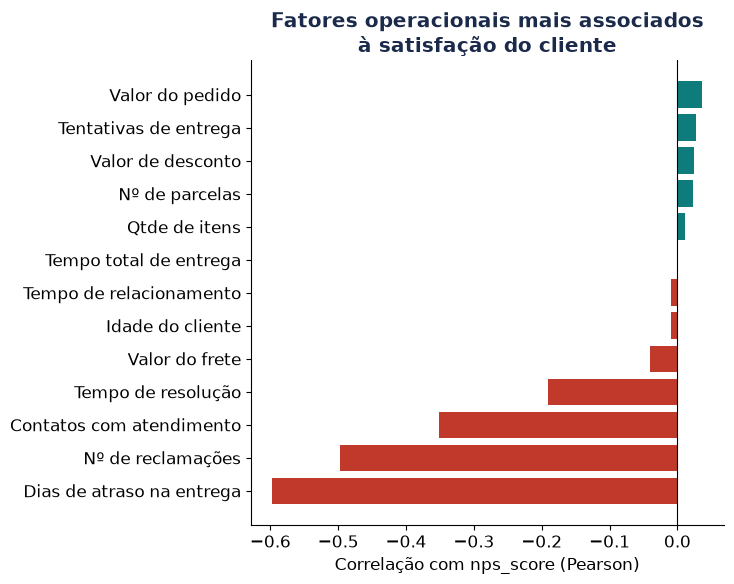

In [6]:
labels_pt = {
 "delivery_delay_days":"Dias de atraso na entrega", "complaints_count":"Nº de reclamações",
 "customer_service_contacts":"Contatos com atendimento", "resolution_time_days":"Tempo de resolução",
 "freight_value":"Valor do frete", "order_value":"Valor do pedido", "delivery_attempts":"Tentativas de entrega",
 "delivery_time_days":"Tempo total de entrega", "discount_value":"Valor de desconto",
 "payment_installments":"Nº de parcelas", "items_quantity":"Qtde de itens",
 "customer_age":"Idade do cliente", "customer_tenure_months":"Tempo de relacionamento",
}
fig, ax = plt.subplots(figsize=(7.5,6))
cores_corr = [RED if v < 0 else TEAL for v in corr.values]
ax.barh([labels_pt[i] for i in corr.index], corr.values, color=cores_corr)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlação com nps_score (Pearson)")
ax.set_title("Fatores operacionais mais associados\nà satisfação do cliente", fontweight="bold", color=NAVY)
plt.tight_layout()
plt.savefig("../reports/05_correlacoes.png", dpi=150)
plt.show()

**Achados:**
- **Dias de atraso na entrega (-0,60)** e **número de reclamações (-0,50)** são, disparadamente, os fatores mais associados a notas baixas.
- **Contatos com o atendimento (-0,35)** e **tempo de resolução (-0,19)** também pioram a satisfação, de forma mais moderada.
- Valor do pedido, quantidade de itens, desconto, parcelamento, tentativas de entrega, idade e tempo de relacionamento têm correlação próxima de zero — ou seja, **não é o perfil do cliente ou o ticket do pedido que explica o NPS, e sim a execução operacional da entrega e do atendimento**.
- `csat_internal_score` (0,56) e `repeat_purchase_30d` (0,57) também têm correlação alta, mas são tratadas com cautela: ver seção 6 sobre risco de vazamento de dado.

## 4. Ponto de ruptura: atraso na entrega

In [7]:
bins = [-1, 0, 2, 5, 100]
rotulos = ["0 dias", "1-2 dias", "3-5 dias", "6+ dias"]
df["faixa_atraso"] = pd.cut(df["delivery_delay_days"], bins=bins, labels=rotulos)

media_por_faixa = df.groupby("faixa_atraso")["nps_score"].mean()
print(media_por_faixa)

composicao = pd.crosstab(df["faixa_atraso"], df["nps_categoria"], normalize="index")[ordem] * 100
print(composicao.round(1))

faixa_atraso
0 dias      6.856679
1-2 dias    5.051308
3-5 dias    2.893633
6+ dias     0.811765
Name: nps_score, dtype: float64
nps_categoria  Detrator  Neutro  Promotor
faixa_atraso                             
0 dias             36.5    32.5      31.0
1-2 dias           67.7    23.7       8.6
3-5 dias           92.8     6.5       0.8
6+ dias           100.0     0.0       0.0


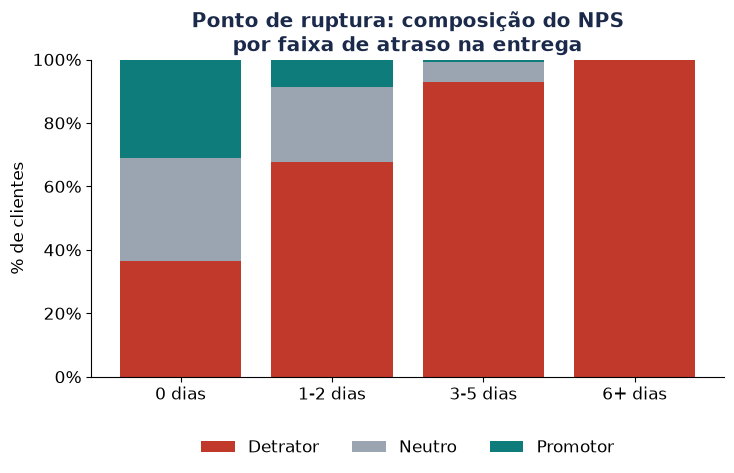

In [8]:
fig, ax = plt.subplots(figsize=(7.5,5))
bottom = None
for cat, cor in zip(ordem, cores):
    vals = composicao[cat].values
    ax.bar(composicao.index.astype(str), vals, bottom=bottom, color=cor, label=cat)
    bottom = vals if bottom is None else bottom + vals
ax.set_ylabel("% de clientes")
ax.set_title("Ponto de ruptura: composição do NPS\npor faixa de atraso na entrega", fontweight="bold", color=NAVY)
ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.15), ncol=3, frameon=False)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.savefig("../reports/03_ruptura_atraso.png", dpi=150)
plt.show()

**Ponto de ruptura identificado:** com entrega no prazo (0 dias de atraso), 31% dos clientes ainda são promotores e "apenas" 37% são detratores. A partir de **3 a 5 dias de atraso, 93% dos clientes viram detratores** e a partir de **6 dias de atraso, 100%** viram detratores, não há mais neutros ou promotores nessa faixa. Esse é o ponto de ruptura da experiência: **o limite operacional aceitável está em até 2 dias de atraso; a partir do 3º dia, a experiência é considerada praticamente perdida.**

## 5. Atendimento: cada contato adicional piora a experiência

customer_service_contacts
0    5.543502
1    4.657108
2    4.116406
3    3.201911
4    2.654545
5    2.238235
6    0.742857
7    1.200000
Name: nps_score, dtype: float64


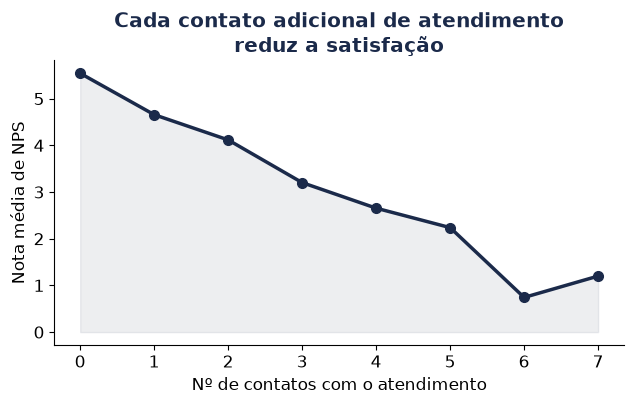

In [9]:
media_contatos = df.groupby("customer_service_contacts")["nps_score"].mean()
print(media_contatos)

fig, ax = plt.subplots(figsize=(6.5,4.2))
ax.plot(media_contatos.index, media_contatos.values, marker="o", color=NAVY, linewidth=2.5, markersize=7)
ax.fill_between(media_contatos.index, media_contatos.values, color=NAVY, alpha=0.08)
ax.set_xlabel("Nº de contatos com o atendimento")
ax.set_ylabel("Nota média de NPS")
ax.set_title("Cada contato adicional de atendimento\nreduz a satisfação", fontweight="bold", color=NAVY)
plt.tight_layout()
plt.savefig("../reports/04_nps_por_contatos.png", dpi=150)
plt.show()

**Achado:** clientes que não precisam contatar o atendimento (0 contatos) têm nota média de 5,5. A cada contato adicional, a nota cai de forma quase linear, chegando a 0,7–1,2 a partir de 6 ou mais contatos. Isso confirma a hipótese de negócio: **o simples fato de o cliente precisar buscar o atendimento, independentemente do motivo, já é, por si só, um sinal de experiência ruim**, mesmo sem atraso na entrega.

## 6. Perfil do cliente e recorte por região

Testamos se clientes novos, mais velhos ou de determinadas regiões concentram notas mais baixas.

In [10]:
df["cliente_novo"] = df["customer_tenure_months"] < 12
print(df.groupby("cliente_novo")["nps_score"].agg(["mean", "count"]))
print()
print(df.groupby("customer_region")["nps_score"].agg(["mean", "count"]).sort_values("mean"))

                  mean  count
cliente_novo                 
False         4.398989   2276
True          4.171429    224

                     mean  count
customer_region                 
Centro-Oeste     4.209829    468
Sudeste          4.373846    520
Norte            4.382609    506
Nordeste         4.421649    485
Sul              4.490979    521


**Achado:** a diferença de NPS médio entre clientes novos (4,17) e demais (4,40) é pequena, e a variação entre regiões também é pequena (de 4,21 no Centro-Oeste a 4,49 no Sul). **Perfil do cliente não é um fator explicativo relevante**, reforça que a causa da insatisfação é operacional (entrega e atendimento), não demográfica.

## 7. Cuidado com vazamento de dado (data leakage)

Duas variáveis têm correlação alta com `nps_score`, mas não devem ser usadas como preditoras de forma ingênua:

In [11]:
print("repeat_purchase_30d por categoria de NPS:")
print(df.groupby("nps_categoria")["repeat_purchase_30d"].mean())
print()
print("Correlação csat_internal_score x nps_score:", df["csat_internal_score"].corr(df["nps_score"]).round(2))

repeat_purchase_30d por categoria de NPS:
nps_categoria
Detrator    0.000000
Neutro      0.037946
Promotor    1.000000
Name: repeat_purchase_30d, dtype: float64

Correlação csat_internal_score x nps_score: 0.56


**Achado crítico:** `repeat_purchase_30d` é **0% para todo detrator, ~4% para neutro e 100% para todo promotor**, ou seja, essa variável praticamente *é* uma transformação do próprio NPS, não uma causa independente. Já `csat_internal_score` tem correlação de 0,56, mas por ser outro indicador interno de satisfação, pode ter sido coletado de forma associada ao mesmo evento, por isso, **ambas as variáveis foram excluídas do modelo preditivo da Fase 4**, para evitar que o modelo "trapaceie" aprendendo a partir do resultado que ele deveria prever.

## 8. Síntese dos achados (linguagem de negócio)

- A empresa tem hoje um NPS de **-66** (74% detratores, 8% promotores), um problema grave e disseminado, não pontual.
- **Atraso na entrega é o fator nº 1**: até 2 dias de atraso a experiência ainda é recuperável; a partir de 3 dias, praticamente 100% dos clientes se tornam detratores.
- **Reclamações e contatos com o atendimento são o fator nº 2**: cada reclamação ou contato adicional reduz a nota de forma consistente, mesmo sem atraso na entrega.
- **Valor do pedido, forma de pagamento, idade e região do cliente não explicam a insatisfação**, o problema é operacional (logística e atendimento), não comercial ou demográfico.
- Esses achados apontam diretamente para a estratégia preditiva da Fase 4: um modelo que sinalize, logo após a confirmação da entrega, o risco de o cliente virar detrator, usando exatamente `delivery_delay_days` e `complaints_count`/`customer_service_contacts` como principais preditores.